<a href="https://colab.research.google.com/github/Dharshanthisside/ITA0616---Machine-learning/blob/main/Exp_10_Expectation_Maximization_(Gaussian_Mixture%2C_from_scratch).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_squared_error, r2_score, mean_absolute_error)

Iter  0: mu=[1.703 7.339], sigma=[0.769 2.161], pi=[0.525 0.475]
Iter 10: mu=[1.876 8.058], sigma=[0.891 1.379], pi=[0.595 0.405]
Iter 20: mu=[1.876 8.058], sigma=[0.891 1.378], pi=[0.595 0.405]
Iter 30: mu=[1.876 8.058], sigma=[0.891 1.378], pi=[0.595 0.405]
Iter 40: mu=[1.876 8.058], sigma=[0.891 1.378], pi=[0.595 0.405]

Final  mu: [1.876 8.058]  sigma: [0.891 1.378]  pi: [0.595 0.405]


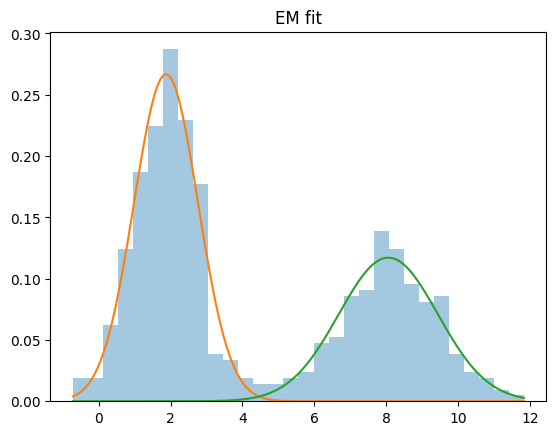

sklearn means: [1.878 8.063]


In [2]:
from scipy.stats import norm

rng = np.random.default_rng(1)
data = np.concatenate([rng.normal(2, 1, 300), rng.normal(8, 1.5, 200)])

# Initial guesses for 2 components
mu = np.array([1.0, 5.0]); sigma = np.array([1.0, 1.0]); pi = np.array([0.5, 0.5])

for it in range(50):
    # E-step: responsibilities
    resp = np.array([pi[k] * norm.pdf(data, mu[k], sigma[k]) for k in range(2)])
    resp /= resp.sum(axis=0)
    # M-step: update parameters
    Nk = resp.sum(axis=1)
    mu = (resp * data).sum(axis=1) / Nk
    sigma = np.sqrt((resp * (data - mu[:, None])**2).sum(axis=1) / Nk)
    pi = Nk / len(data)
    if it % 10 == 0:
        print(f"Iter {it:2d}: mu={mu.round(3)}, sigma={sigma.round(3)}, pi={pi.round(3)}")

print("\nFinal  mu:", mu.round(3), " sigma:", sigma.round(3), " pi:", pi.round(3))

x = np.linspace(data.min(), data.max(), 500)
plt.hist(data, bins=30, density=True, alpha=0.4)
for k in range(2):
    plt.plot(x, pi[k] * norm.pdf(x, mu[k], sigma[k]))
plt.title('EM fit'); plt.show()

# Cross-check with sklearn
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(2, random_state=0).fit(data.reshape(-1, 1))
print("sklearn means:", gm.means_.ravel().round(3))